In [143]:
import numpy as np #bibliothèque pour tableaux de nombres
import matplotlib.pyplot as plt #bibliothèque pour graphiques
import math

In [144]:
#Paramètres initiaux
duree = 500 #durée de simulation 
K0 = 1 #capital productif à t0
S0 = 1 #services à t0
R0 = 1 #ressources non renouvelables à t0
P0 = 1 #population à t0
E0 = 0.3 #pollution à t0

#Définition de la production
A = 0.5 #PGF
alphaCD = 0.3 #part du capital dans la Cobb-Douglas
g = 0.0 #progrès technique sur l'efficacité du capital à produire et à polluer moins
deltaK = 0.04 #dépréciation capital
extract = 1.03 #vitesse de hausse des coûts d'extraction
efficacitern0 = 40 #capacité initiale à produire du Y avec du R
renouvelables = 0.02 #taux de renouvellement des ressources

#Répartition de la production
fioacs = 0.7 #part de la production vers la conso et les services
fioaa = 0.01 #part de la production vers l'agriculture
fioai = 0.25 #part de la production vers le capital (investissement)

#Services, naissances, décès
deltaS = 0.04 #dépréciation services
n = 0.016 #taux de natalité normal
nmin = 0.009 # natalité plancher
n2 = 0.05 #variation natalité selon pollution 
d = 0.009 #taux de décès normal
dmin = 0.007 #mortalité plancher
d2 = 0.1 #variation décès selon pollution
d3 = 4 #variation décès selon nourriture
ks = 1 #niveau de service par habitant pour moitié de l'effet

#Bloc agriculture
T = 1 #surface en terre cultivable
rendement = 0.8 #rendement agricole par unité de terre
Ey = 0.05 #variation du rendement agricole avec la pollution
besoin = 1 #seuil alimentaire
saturation = 0.05 #seuil de saturation des intrants
efficaciteagri = 2 #variation de la prod selon les investissements agricoles 

#Bloc pollutions
YE = 0.05 #pollutions émises par la production
rE = 0.05 #pollutions émises par l'agriculture 
deltaE = 0.05 #absorbtion de la pollution capacité décroissante)(


In [145]:
#Tableaux d'historique

annee = np.arange(duree + 1)
K = np.zeros(duree + 1)
R = np.zeros(duree + 1)
S = np.zeros(duree + 1)
P = np.zeros(duree + 1)
E = np.zeros(duree + 1)
Y = np.zeros(duree + 1)
prodagricole = np.zeros(duree + 1)
SsurP = np.zeros(duree + 1) #production économique par habitant
AsurP = np.zeros(duree + 1) #production agricole par habitant
fcaor = np.zeros(duree + 1)

K[0] = K0
R[0] = R0
S[0] = S0
P[0] = P0
E[0] = E0

In [146]:
#Boucle d'équations
for i in range(duree):
    t = annee[i]
    k, r, s, p, e = K[i], R[i], S[i], P[i], E[i]
    
    fcaor[i] = 1-(r/R0)**extract #capital pour ressources naturelles
    Ypot = (A*np.exp(g*t))*(k*(1-fcaor[i]))**alphaCD * p**(1-alphaCD)
    efficacite = efficacitern0*(np.exp(g*t))
    Ymax = r*efficacite
    Y[i] = min (Ypot, Ymax)
    
    prodagricole[i] = T*rendement*(1+efficaciteagri*(fioaa*Y[i]/T)/(fioaa*Y[i]/T+saturation))/(1+Ey*e)
    AsurP[i] = prodagricole[i] / p
    
    SsurP[i] = s / p
    saturationservices = SsurP[i] / (SsurP[i] + ks)           
    natalite = n - (n - nmin) * saturationservices       
    mortalite = d - (d - dmin) * saturationservices      
    famine = max(0, (besoin - AsurP[i]) / besoin)        
    naissances = p * natalite * np.exp(-n2*e)
    deces = p * mortalite * (1 + d2*e) * (1 + d3*famine)

    K[i + 1] = k + (fioai * Y[i] - k*deltaK)
    R[i + 1] = r+ r*renouvelables*(1-r/R0) - min((Y[i]/(efficacitern0*np.exp(g*t))),r)
    S[i + 1] = s + (fioacs * Y[i] - s*deltaS)
    P[i + 1] = p + naissances - deces
    E [i + 1] = e + (YE/(1+g*t))*Y[i] + rE*prodagricole[i] - e*deltaE

    

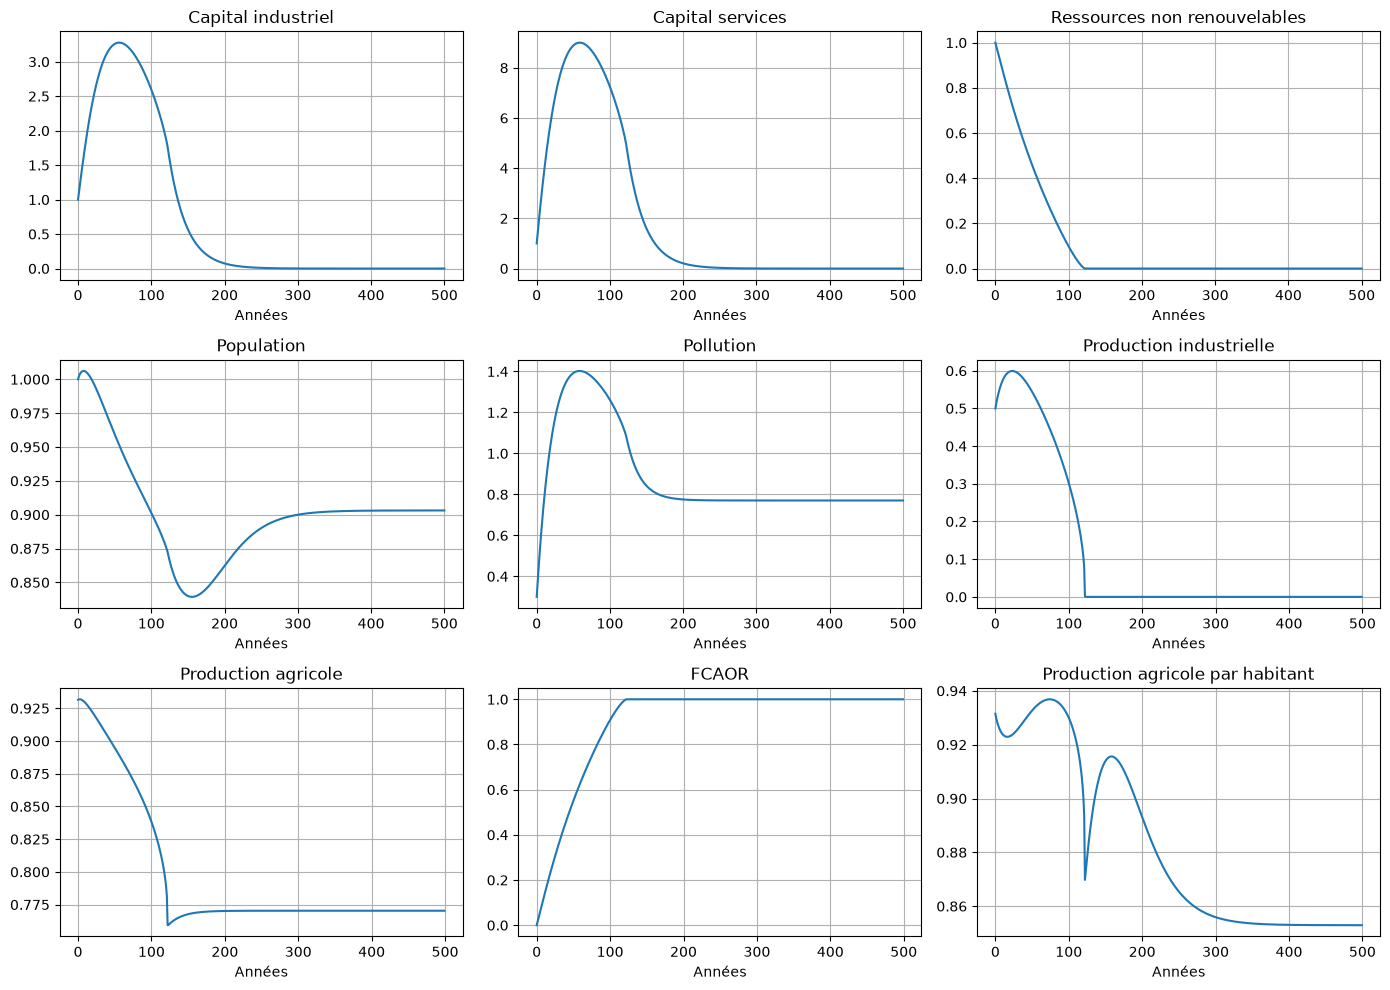

In [147]:
#Graphique
fig, axes = plt.subplots(3, 3, figsize=(14, 10))

# Stocks : définis pour les duree + 1 dates (de 0 à duree)
stocks = [
    ("Capital industriel", K),
    ("Capital services", S),
    ("Ressources non renouvelables", R),
    ("Population", P),
    ("Pollution", E),
]

# Variables calculées dans la boucle : définies seulement pour les duree premières dates
flux = [
    ("Production industrielle", Y),
    ("Production agricole", prodagricole),
    ("FCAOR", fcaor),
    ("Production agricole par habitant", AsurP),
]

# Chaque courbe devient un triplet (titre, dates, valeurs)
courbes = [(titre, annee, serie) for titre, serie in stocks] \
        + [(titre, annee[:-1], serie[:-1]) for titre, serie in flux]

for ax, (titre, x, serie) in zip(axes.flat, courbes):
    ax.plot(x, serie)
    ax.set_title(titre)
    ax.set_xlabel("Années")
    ax.grid(True)

plt.tight_layout()
plt.show()